# IBM Telco Customer Churn: EDA, Preprocessing, Baselines, Tuning and Final Test Result

**Course:** DATA 4380 group project (UT Arlington) · **Dataset:** IBM Telco sample data (7,043 customers, 21 columns, 26.5% churn)

**What this notebook does:** explore the data, compare three `TotalCharges` strategies, build baseline models, tune Logistic Regression / Random Forest / XGBoost, test feature selection, SMOTE and a tuned cutoff, then score the test set once.

**How we decide:** all choices use 5-fold stratified cross-validation on the training set. The 20% test set is touched only once, at the end.

Run top to bottom. Data download and environment instructions are in the repository README.

---
# Part 1. Explore the data

### Import libraries

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

### Load the data

In [4]:
from pathlib import Path

# Put the CSV in tabular/data/ (see README). The other paths let the notebook run from Colab or the same folder.
DATA_PATH = next(p for p in ["/content/WA_Fn-UseC_-Telco-Customer-Churn.csv"] if Path(p).exists())

df_raw = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_raw.shape)
df_raw.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Exploratory data analysis (EDA)

We explore the data before changing it. This helps us understand the target, distributions, and potential relationships.

### Dataset overview

In [5]:
df_raw.shape

(7043, 21)

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### Target distribution

In [7]:
df_raw["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [8]:
df_raw["Churn"].value_counts(normalize=True).mul(100).round(2)

,proportion
Churn,
No,73.46
Yes,26.54


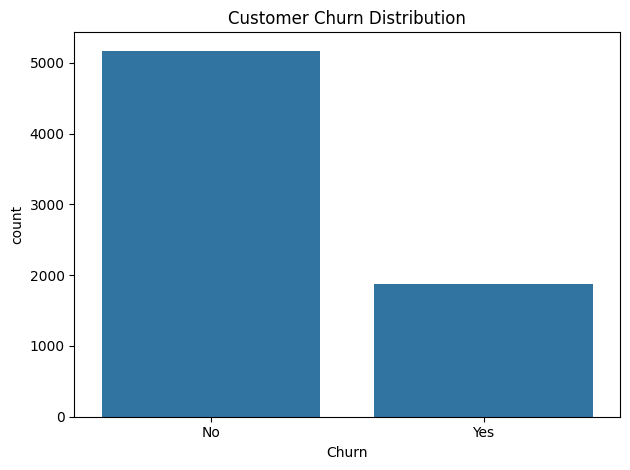

In [9]:
sns.countplot(data=df_raw, x="Churn")
plt.title("Customer Churn Distribution")
plt.tight_layout()
plt.show()

### Numerical feature distributions

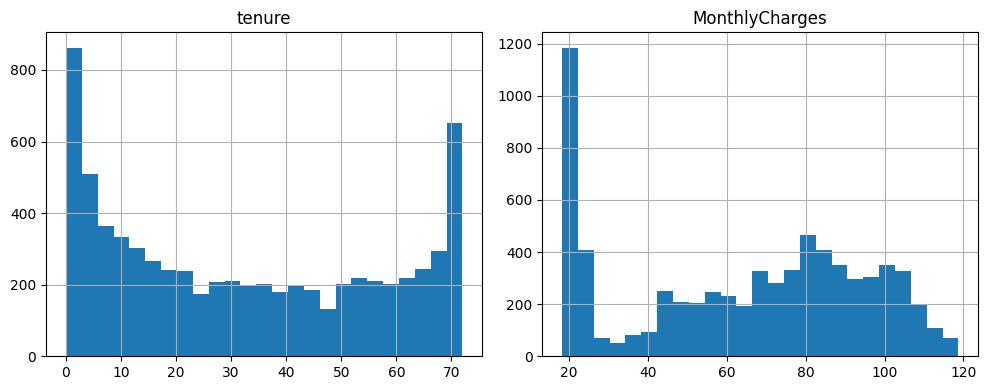

In [10]:
df_raw[["tenure", "MonthlyCharges"]].hist(figsize=(10, 4), bins=25)
plt.tight_layout()
plt.show()

### Churn across selected customer groups

In [11]:
pd.crosstab(df_raw["Contract"], df_raw["Churn"], normalize="index").mul(100).round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [12]:
pd.crosstab(df_raw["InternetService"], df_raw["Churn"], normalize="index").mul(100).round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [13]:
pd.crosstab(df_raw["PaymentMethod"], df_raw["Churn"], normalize="index").mul(100).round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


These are descriptive checks only. We will do model-based comparisons after the baseline and preprocessing steps.

---
# Part 2. Clean the data and split

### Inspect the 11 blank `TotalCharges` values

In [14]:
blank_mask = df_raw["TotalCharges"].astype(str).str.strip().eq("")
blank_rows = df_raw.loc[
    blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

print("Blank TotalCharges rows:", len(blank_rows))
blank_rows

Blank TotalCharges rows: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


The blank values are stored as spaces, so `isnull()` will not detect them yet. We will convert `TotalCharges` to numeric and let those spaces become missing values.

### Clean the shared columns

In [15]:
df = df_raw.copy()

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())

TotalCharges data type: float64
Missing TotalCharges: 11
Exact duplicate rows: 0


### Baseline before the planned preprocessing

We establish a baseline using the raw feature values (apart from converting `TotalCharges` to numeric). This gives us a reference point to compare against later preprocessing improvements. The split happens before fitting imputers, encoders, or scalers.

In [16]:
df_baseline = df.copy()
df_baseline = df_baseline.drop(columns="customerID")
y_baseline = (df_baseline["Churn"] == "Yes").astype(int)
X_baseline = df_baseline.drop(columns="Churn")

X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(
    X_baseline, y_baseline, test_size=0.20, stratify=y_baseline, random_state=RANDOM_STATE
)
print("Training set:", X_train_base.shape)
print("Test set:", X_test_base.shape)

Training set: (5634, 19)
Test set: (1409, 19)


### Baseline Logistic Regression

In [17]:
def make_preprocessor(X_part, numeric_imputer="median"):
    numeric_columns = X_part.select_dtypes(include="number").columns.tolist()
    categorical_columns = X_part.select_dtypes(exclude="number").columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy=numeric_imputer)),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns)
    ], sparse_threshold=0)

base_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_pipe = Pipeline([
    ("preprocess", make_preprocessor(X_train_base, "median")),
    ("model", LogisticRegression(max_iter=3000))
])
base_scores = cross_validate(base_pipe, X_train_base, y_train_base, cv=base_cv, scoring={
    "accuracy": "accuracy", "precision": "precision", "recall": "recall",
    "f1": "f1", "roc_auc": "roc_auc"
}, n_jobs=-1)
pd.DataFrame({metric: [values.mean()] for metric, values in base_scores.items() if metric.startswith("test_")}, index=["Baseline CV"]).T

,Baseline CV
test_accuracy,0.802096
test_precision,0.652899
test_recall,0.543144
test_f1,0.592316
test_roc_auc,0.846137


This is our reference score. After preprocessing, we will compare the same metrics to see whether the changes actually help.

### Simplify service categories

In [18]:
service_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies"
]

df[service_cols] = df[service_cols].replace({"No internet service": "No"})
df["MultipleLines"] = df["MultipleLines"].replace({"No phone service": "No"})

df[service_cols + ["MultipleLines"]].head()

,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines
0,No,Yes,No,No,No,No,No
1,Yes,No,Yes,No,No,No,No
2,Yes,Yes,No,No,No,No,No
3,Yes,No,Yes,Yes,No,No,No
4,No,No,No,No,No,No,No


This combines service-specific “no service” labels into “No”. The separate `InternetService` and `PhoneService` columns already tell us whether the customer has those services.

### Check the missing rows before imputing

In [19]:
df.loc[df["TotalCharges"].isna(),
       ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


All 11 rows have zero tenure. For these rows, `MonthlyCharges × tenure` gives zero. We will compare that targeted fill against mean and median imputation. We will not create a new product feature for every customer.

### Create the target and remove the identifier

In [20]:
df = df.drop(columns="customerID")

y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns="Churn")

print("Features:", X.shape)
print("Target:", y.shape)
print("Churn rate:", round(y.mean() * 100, 2), "%")

Features: (7043, 19)
Target: (7043,)
Churn rate: 26.54 %


### Split into training and test sets

In [21]:
# Decision: split FIRST (stratified 80/20) so the test set never influences imputation, scaling, encoding, tuning or the cutoff.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Test churn rate:", round(y_test.mean() * 100, 2), "%")

Training set: (5634, 19)
Test set: (1409, 19)
Training churn rate: 26.54 %
Test churn rate: 26.54 %


We make this split before fitting imputers, scalers, encoders, or models. The test set will only be used after we finish choosing and tuning the models.

### Churn rate by group (training set)

These are the rates behind the “patterns” slide, computed on the training set.

In [22]:
# Churn rate by customer group in the TRAINING set (the chart on the "patterns" slide)
view = X_train.copy()
view["Churn"] = y_train
groups = {
    "First 12 months of tenure": view["tenure"] <= 12,
    "Electronic check":          view["PaymentMethod"] == "Electronic check",
    "Month-to-month contract":   view["Contract"] == "Month-to-month",
    "Fiber optic internet":      view["InternetService"] == "Fiber optic",
    "Two-year contract":         view["Contract"] == "Two year",
}
rates = pd.Series({k: view.loc[m, "Churn"].mean() * 100 for k, m in groups.items()})
rates["All customers"] = y_train.mean() * 100
rates.sort_values(ascending=False).round(1).rename("Churn rate %")

,Churn rate %
First 12 months of tenure,47.3
Electronic check,45.7
Month-to-month contract,42.7
Fiber optic internet,42.1
All customers,26.5
Two-year contract,2.9


### Correlation heatmap before encoding

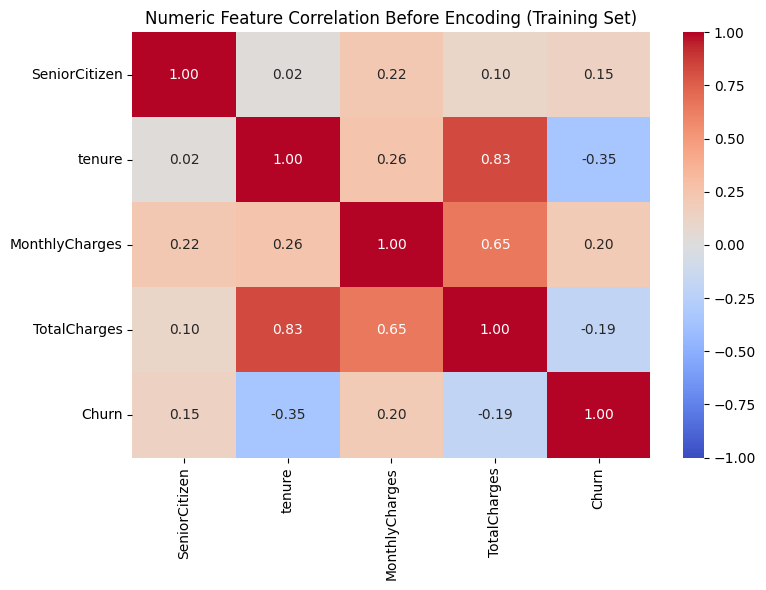

In [23]:
train_for_corr = X_train.copy()
train_for_corr["Churn"] = y_train

numeric_corr = train_for_corr.select_dtypes(include="number").corr()

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1)
plt.title("Numeric Feature Correlation Before Encoding (Training Set)")
plt.tight_layout()
plt.show()

This heatmap covers numerical columns only. Categorical columns such as `Contract` and `PaymentMethod` are not included until they are encoded.

---
# Part 3. Preprocessing pipelines and `TotalCharges` strategies

### Build the three `TotalCharges` strategies

In [24]:
# Strategy A1: keep tenure, MonthlyCharges, and TotalCharges; median-impute TotalCharges
X_A_median = X_train.copy()
X_A_median_test = X_test.copy()

# Strategy A2: same features, but mean-impute TotalCharges
X_A_mean = X_train.copy()
X_A_mean_test = X_test.copy()

# Strategy B: fill only missing TotalCharges values using MonthlyCharges * tenure,
# then remove tenure and MonthlyCharges.
X_B = X_train.copy()
X_B_test = X_test.copy()

for frame in (X_B, X_B_test):
    missing = frame["TotalCharges"].isna()
    frame.loc[missing, "TotalCharges"] = (
        frame.loc[missing, "MonthlyCharges"] * frame.loc[missing, "tenure"]
    )

X_B = X_B.drop(columns=["tenure", "MonthlyCharges"])
X_B_test = X_B_test.drop(columns=["tenure", "MonthlyCharges"])

print("A (median) features:", X_A_median.shape[1])
print("A (mean) features:", X_A_mean.shape[1])
print("B (product-fill, drop two columns) features:", X_B.shape[1])
print("Missing in B training data:", X_B.isna().sum().sum())

A (median) features: 19
A (mean) features: 19
B (product-fill, drop two columns) features: 17
Missing in B training data: 0


The product is used **only where `TotalCharges` is missing**. It does not replace `TotalCharges` for customers who already have a recorded value.

For Strategy B, the missing-value fill is a deterministic calculation from that row's own values, not a statistic learned from the full dataset.

### Create preprocessing pipelines

In [25]:
# Decision: imputing, scaling and one-hot encoding live inside a Pipeline, so every CV fold refits them on its own training rows only (no leakage).
def make_preprocessor(X_part, numeric_imputer="median"):
    numeric_columns = X_part.select_dtypes(include="number").columns.tolist()
    categorical_columns = X_part.select_dtypes(exclude="number").columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy=numeric_imputer)),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns)
    ], sparse_threshold=0)

    return preprocessor

prep_A_median = make_preprocessor(X_A_median, "median")
prep_A_mean = make_preprocessor(X_A_mean, "mean")
prep_B = make_preprocessor(X_B, "median")

print("Categorical columns will be one-hot encoded, including Contract and PaymentMethod.")
print("OneHotEncoder handles categories not seen during training with handle_unknown='ignore'.")

Categorical columns will be one-hot encoded, including Contract and PaymentMethod.
OneHotEncoder handles categories not seen during training with handle_unknown='ignore'.


### Correlation heatmap after encoding

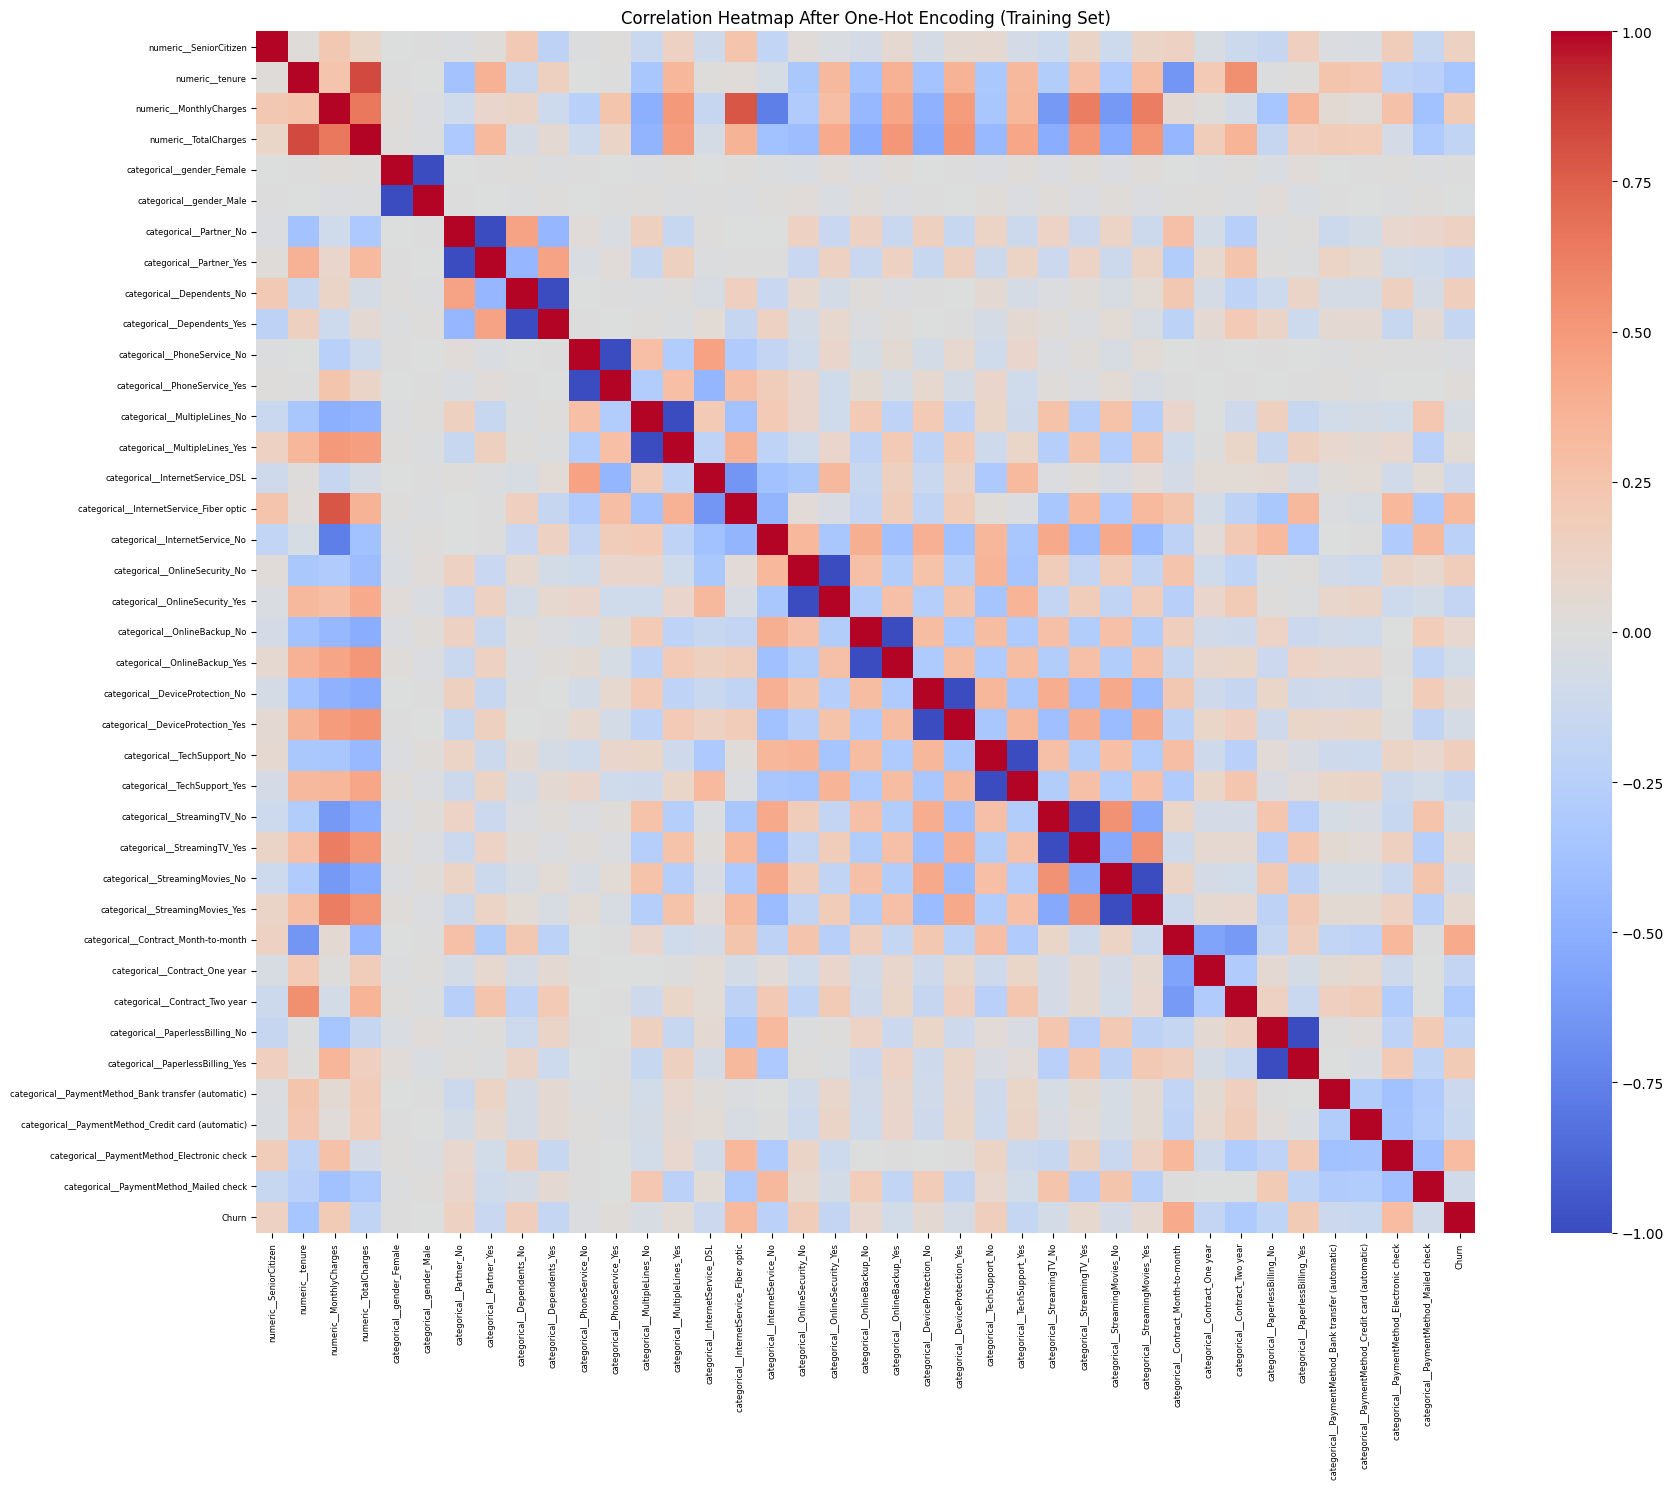

In [26]:
encoded_train = prep_A_median.fit_transform(X_A_median)

encoded_names = prep_A_median.get_feature_names_out()
encoded_df = pd.DataFrame(encoded_train, columns=encoded_names, index=X_A_median.index)
encoded_df["Churn"] = y_train

encoded_corr = encoded_df.corr()

plt.figure(figsize=(18, 15))
sns.heatmap(encoded_corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
plt.title("Correlation Heatmap After One-Hot Encoding (Training Set)")
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)
plt.tight_layout()
plt.show()

One-hot encoding creates a separate 0/1 column for each category. `Contract` and `PaymentMethod` have only a few categories, so the added number of columns is manageable. The heatmap is larger now because it includes the encoded categorical columns.

### Define evaluation metrics

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

### Compare imputation / feature strategies with baseline Logistic Regression

In [28]:
strategy_data = {
    "A - Median imputation, keep all three": (X_A_median, prep_A_median),
    "A - Mean imputation, keep all three": (X_A_mean, prep_A_mean),
    "B - Product-fill missing rows, drop tenure and MonthlyCharges": (X_B, prep_B)
}

strategy_rows = []

for strategy_name, (X_part, prep) in strategy_data.items():
    pipe = Pipeline([
        ("preprocess", prep),
        ("model", LogisticRegression(max_iter=3000, class_weight=None))
    ])

    scores = cross_validate(
        pipe, X_part, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )

    strategy_rows.append({
        "Strategy": strategy_name,
        "Features before encoding": X_part.shape[1],
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

strategy_results = pd.DataFrame(strategy_rows).set_index("Strategy").sort_values(
    ["CV F1", "CV ROC-AUC"], ascending=False
)
strategy_results.round(3)

,Features before encoding,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
Strategy,,,,,,
"A - Median imputation, keep all three",19,0.802,0.653,0.543,0.592,0.846
"A - Mean imputation, keep all three",19,0.802,0.653,0.543,0.592,0.846
"B - Product-fill missing rows, drop tenure and MonthlyCharges",17,0.798,0.646,0.526,0.580,0.840


### Result: `TotalCharges` strategies

| Strategy | CV F1 |
|---|---|
| **Median fill, keep all three columns** | **0.592** |
| Mean fill, keep all three columns | 0.592 |
| Product fill, drop `tenure` and `MonthlyCharges` | 0.580 |

> **Takeaway:** median and mean fill score the same, and the product fill is slightly worse. We use the **median fill**.

We compare the strategies using training-set cross-validation, not the test set. F1 balances precision and recall; ROC-AUC measures how well the model ranks churners above non-churners.

### Choose a strategy for the initial model comparison

In [29]:
chosen_strategy = strategy_results.index[0]
print("Best Logistic Regression strategy by CV F1, then ROC-AUC:")
print(chosen_strategy)

Best Logistic Regression strategy by CV F1, then ROC-AUC:
A - Median imputation, keep all three


This is a provisional choice based on Logistic Regression cross-validation. We will later check whether the choice remains sensible when we compare the other model families.

### Prepare the selected strategy

In [30]:
if chosen_strategy.startswith("A - Median"):
    X_train_model, X_test_model = X_A_median.copy(), X_A_median_test.copy()
    chosen_imputer = "median"
elif chosen_strategy.startswith("A - Mean"):
    X_train_model, X_test_model = X_A_mean.copy(), X_A_mean_test.copy()
    chosen_imputer = "mean"
else:
    X_train_model, X_test_model = X_B.copy(), X_B_test.copy()
    chosen_imputer = "median"

preprocess = make_preprocessor(X_train_model, chosen_imputer)

print("Selected strategy:", chosen_strategy)
print("Training features:", X_train_model.shape[1])
print("Test features:", X_test_model.shape[1])

Selected strategy: A - Median imputation, keep all three
Training features: 19
Test features: 19


---
# Part 4. Baseline models

### Baseline models

In [31]:
baseline_models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    )
}

baseline_pipelines = {
    name: Pipeline([
        ("preprocess", make_preprocessor(X_train_model, chosen_imputer)),
        ("model", model)
    ])
    for name, model in baseline_models.items()
}

### Baseline cross-validation results

In [32]:
baseline_rows = []

for name, pipe in baseline_pipelines.items():
    scores = cross_validate(
        pipe, X_train_model, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    baseline_rows.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "F1 standard deviation": scores["test_f1"].std()
    })

baseline_results = pd.DataFrame(baseline_rows).set_index("Model").sort_values(
    "CV F1", ascending=False
)
baseline_results.round(3)

,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,F1 standard deviation
Model,,,,,,
Logistic Regression,0.802,0.653,0.543,0.592,0.846,0.030
Random Forest,0.786,0.627,0.482,0.545,0.823,0.031
Dummy,0.735,0.000,0.000,0.000,0.500,0.000


### Result: baseline models (5-fold CV)

| Model | F1 | Recall | ROC-AUC |
|---|---|---|---|
| Dummy | 0.000 | 0.000 | 0.500 |
| **Logistic Regression** | **0.592** | 0.543 | 0.846 |
| Random Forest | 0.545 | 0.482 | 0.823 |

> **Takeaway:** simple was enough. Contract, tenure and payment method carry strong, simple signals, so Logistic Regression beat the Random Forest at the baseline.

### Check whether preprocessing improves the baseline

This compares the raw-data Logistic Regression baseline with Logistic Regression after the chosen preprocessing strategy, using the same training split and cross-validation setup.

In [33]:
baseline_cv_scores = cross_validate(
    base_pipe, X_train_base, y_train_base, cv=cv, scoring=scoring, n_jobs=-1
)
processed_pipe = Pipeline([
    ("preprocess", make_preprocessor(X_train_model, chosen_imputer)),
    ("model", LogisticRegression(max_iter=3000))
])
processed_cv_scores = cross_validate(
    processed_pipe, X_train_model, y_train, cv=cv, scoring=scoring, n_jobs=-1
)

pd.DataFrame({
    "Baseline before preprocessing": {m: baseline_cv_scores[f"test_{m}"].mean() for m in scoring},
    "After preprocessing": {m: processed_cv_scores[f"test_{m}"].mean() for m in scoring}
}).T.round(3)

,accuracy,precision,recall,f1,roc_auc
Baseline before preprocessing,0.802,0.653,0.543,0.592,0.846
After preprocessing,0.802,0.653,0.543,0.592,0.846


In [34]:
models_to_tune = {
    "Logistic Regression": (
        LogisticRegression(max_iter=4000),
        {
            "model__C": [0.01, 0.1, 1, 10, 100],
            "model__class_weight": [None, "balanced"],
            "model__solver": ["liblinear", "lbfgs"]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {
            "model__n_estimators": [200, 400, 600],
            "model__max_depth": [None, 5, 10, 20],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "model__class_weight": [None, "balanced", "balanced_subsample"]
        }
    )
}
from xgboost import XGBClassifier
models_to_tune["XGBoost"] = (
        XGBClassifier(
            random_state=RANDOM_STATE,
            eval_metric="logloss",
            n_jobs=-1
        ),
        {
            "model__n_estimators": [200, 400, 600],
            "model__max_depth": [2, 3, 5, 7],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__subsample": [0.7, 0.9, 1.0],
            "model__colsample_bytree": [0.7, 0.9, 1.0]
        }
    )

list(models_to_tune.keys())

['Logistic Regression', 'Random Forest', 'XGBoost']

---
# Part 5. Tune the models

We tune on the training data with stratified cross-validation. `class_weight` is included for Logistic Regression and Random Forest because churn is the minority class. We will compare metrics rather than assume that balancing is always better.

### Tune each model

In [35]:
tuning_results = {}
tuning_rows = []

for model_name, (model, param_distributions) in models_to_tune.items():
    pipe = Pipeline([
        ("preprocess", make_preprocessor(X_train_model, chosen_imputer)),
        ("model", model)
    ])

    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_distributions,
        n_iter=12,
        scoring="f1",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    search.fit(X_train_model, y_train)
    tuning_results[model_name] = search

    tuning_rows.append({
        "Model": model_name,
        "Best CV F1": search.best_score_,
        "Best parameters": search.best_params_
    })

tuning_summary = pd.DataFrame(tuning_rows).set_index("Model").sort_values(
    "Best CV F1", ascending=False
)
tuning_summary

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits


,Best CV F1,Best parameters
Model,,
Logistic Regression,0.633367,"{'model__solver': 'lbfgs', 'model__class_weigh..."
Random Forest,0.631159,"{'model__n_estimators': 600, 'model__min_sampl..."
XGBoost,0.597948,"{'model__subsample': 0.7, 'model__n_estimators..."


Randomized search tests a manageable sample of parameter combinations instead of every possible combination. The best settings are selected using cross-validated F1 on the training data.

### Compare tuned models on cross-validation

In [36]:
tuned_cv_rows = []

for model_name, search in tuning_results.items():
    best_pipe = search.best_estimator_
    scores = cross_validate(
        best_pipe, X_train_model, y_train, cv=cv, scoring=scoring, n_jobs=-1
    )
    tuned_cv_rows.append({
        "Model": model_name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

tuned_cv_results = pd.DataFrame(tuned_cv_rows).set_index("Model").sort_values(
    ["CV F1", "CV ROC-AUC"], ascending=False
)
tuned_cv_results.round(3)

,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
Model,,,,,
Logistic Regression,0.757,0.528,0.791,0.633,0.843
Random Forest,0.782,0.572,0.704,0.631,0.843
XGBoost,0.808,0.674,0.538,0.598,0.850


### Result: tuned models (5-fold CV)

| Model | Recall | Precision | F1 | ROC-AUC |
|---|---|---|---|---|
| **Logistic Regression** | 0.791 | 0.528 | **0.633** | 0.843 |
| Random Forest | 0.704 | 0.572 | 0.631 | 0.843 |
| XGBoost | 0.537 | 0.670 | 0.596 | 0.850 |

> **Takeaway:** class weights raise Logistic Regression’s recall from 0.54 to 0.79 and its F1 from 0.592 to 0.633, but precision falls to 0.53. Tuned Random Forest and XGBoost are no better than Logistic Regression.

### Fit the selected model for exploratory interpretation

The test set is still untouched here. This fit is only used for the exploratory feature-importance ranking below. The final test evaluation is at the end of the notebook.

In [37]:
best_model_name = tuned_cv_results.index[0]
best_model = tuning_results[best_model_name].best_estimator_

print("Selected model based on training cross-validation:", best_model_name)
best_model.fit(X_train_model, y_train)

Selected model based on training cross-validation: Logistic Regression


Pipeline(steps=[('preprocess',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod'])])),
                ('model',
                 LogisticRegression(C=0.01, class_weight='balanced',
                                    max_iter=4000))])

The ranking below uses training data, so it may be optimistic. The final test-set evaluation comes at the end of the notebook, after the model and feature set are fixed.

### Feature importance

In [38]:
importance_result = permutation_importance(
    best_model,
    X_train_model,
    y_train,
    scoring="f1",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance = pd.Series(
    importance_result.importances_mean,
    index=X_train_model.columns
).sort_values(ascending=False)

importance.head(15)

,0
tenure,0.069761
MonthlyCharges,0.030861
Contract,0.021310
InternetService,0.019954
OnlineSecurity,0.007344
PaymentMethod,0.006680
TechSupport,0.005272
PaperlessBilling,0.004908
Dependents,0.003600
PhoneService,0.002374


Permutation importance measures how much the model's F1 score drops when one original column is shuffled. This is an exploratory ranking on the training set, so it may be optimistic.

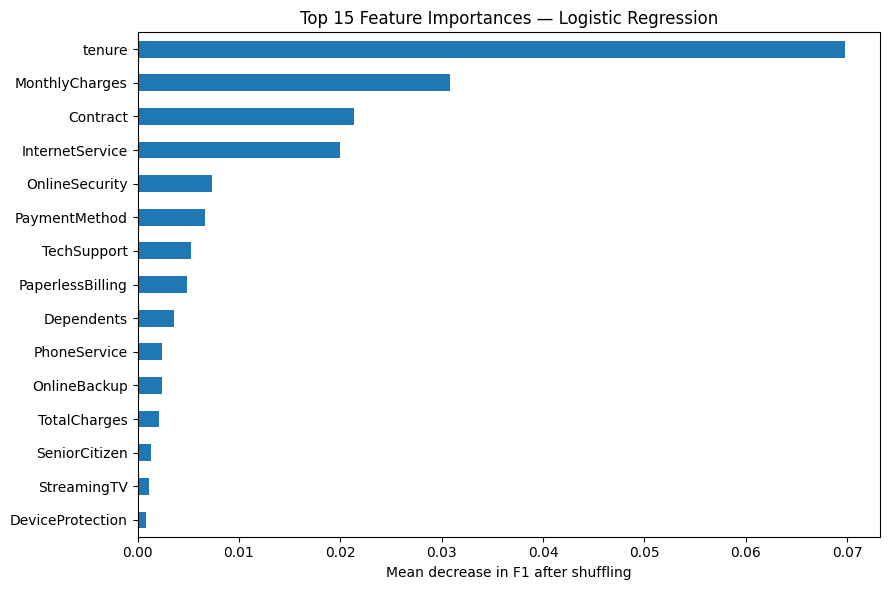

In [39]:
top_importance = importance.head(15).sort_values()

plt.figure(figsize=(9, 6))
top_importance.plot(kind="barh")
plt.xlabel("Mean decrease in F1 after shuffling")
plt.title(f"Top 15 Feature Importances — {best_model_name}")
plt.tight_layout()
plt.show()

---
# Part 6. Feature selection (ANOVA and Chi-square)

### ANOVA F-test and Chi-square feature selection

These are filter methods. They score features individually against the target. We fit them on the training data only, then compare Logistic Regression with all features against selected features using cross-validation.

### Prepare encoded training features for selection

In [40]:
from sklearn.feature_selection import SelectKBest, f_classif, chi2

selection_preprocessor = make_preprocessor(X_train_model, chosen_imputer)
X_train_encoded = selection_preprocessor.fit_transform(X_train_model)
encoded_feature_names = selection_preprocessor.get_feature_names_out()

# Chi-square requires non-negative values, so use a separate encoder without standard scaling.
num_cols = X_train_model.select_dtypes(include="number").columns.tolist()
cat_cols = X_train_model.select_dtypes(exclude="number").columns.tolist()
selection_preprocessor_chi2 = ColumnTransformer([
    ("numeric", SimpleImputer(strategy=chosen_imputer), num_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
], sparse_threshold=0)
X_train_encoded_chi2 = selection_preprocessor_chi2.fit_transform(X_train_model)
chi2_feature_names = selection_preprocessor_chi2.get_feature_names_out()

print("Encoded feature count for ANOVA:", X_train_encoded.shape[1])
print("Encoded feature count for Chi-square:", X_train_encoded_chi2.shape[1])

Encoded feature count for ANOVA: 38
Encoded feature count for Chi-square: 38


### ANOVA F-test ranking

In [41]:
anova_selector = SelectKBest(score_func=f_classif, k="all")
anova_selector.fit(X_train_encoded, y_train)

anova_results = pd.DataFrame({
    "Feature": encoded_feature_names,
    "F-score": anova_selector.scores_,
    "p-value": anova_selector.pvalues_
}).sort_values("F-score", ascending=False)

anova_results.head(20)

,Feature,F-score,p-value
29,categorical__Contract_Month-to-month,1114.220194,4.455069e-223
1,numeric__tenure,763.890183,8.634920e-158
15,categorical__InternetService_Fiber optic,610.199922,5.320291e-128
36,categorical__PaymentMethod_Electronic check,595.424491,4.255626e-125
31,categorical__Contract_Two year,566.070664,2.613128e-119
16,categorical__InternetService_No,311.490238,6.768641e-68
2,numeric__MonthlyCharges,229.903823,6.266598e-51
33,categorical__PaperlessBilling_Yes,229.761099,6.713317e-51
32,categorical__PaperlessBilling_No,229.761099,6.713317e-51
3,numeric__TotalCharges,221.208303,4.173581e-49


ANOVA evaluates whether a numerical feature's mean differs between the two target groups. Here it is applied to the encoded columns; one-hot columns are binary indicators, so interpret this as a univariate ranking rather than a causal result.

### Chi-square ranking

In [42]:
chi2_selector = SelectKBest(score_func=chi2, k="all")
chi2_selector.fit(X_train_encoded_chi2, y_train)

chi2_results = pd.DataFrame({
    "Feature": chi2_feature_names,
    "Chi-square score": chi2_selector.scores_,
    "p-value": chi2_selector.pvalues_
}).sort_values("Chi-square score", ascending=False)

chi2_results.head(20)

,Feature,Chi-square score,p-value
3,numeric__TotalCharges,479959.665325,0.000000e+00
1,numeric__tenure,12501.193952,0.000000e+00
2,numeric__MonthlyCharges,3090.537424,0.000000e+00
29,categorical__Contract_Month-to-month,418.190550,6.043612e-93
31,categorical__Contract_Two year,390.436350,6.650946e-87
36,categorical__PaymentMethod_Electronic check,357.880512,8.148919e-80
15,categorical__InternetService_Fiber optic,308.022809,5.887716e-69
16,categorical__InternetService_No,231.646187,2.608207e-52
30,categorical__Contract_One year,143.681131,4.171643e-33
32,categorical__PaperlessBilling_No,130.563871,3.084461e-30


Chi-square requires non-negative inputs, so the numeric columns are not standardized for this test. The test measures association between each feature and churn, not causation.

### Compare feature selection sizes with cross-validation

In [43]:
k_values = [10, 20, 30]
selection_comparison = []

for method_name, score_function in [("ANOVA", f_classif), ("Chi-square", chi2)]:
    for k in k_values:
        if method_name == "ANOVA":
            prep_for_method = make_preprocessor(X_train_model, chosen_imputer)
        else:
            prep_for_method = ColumnTransformer([
                ("numeric", SimpleImputer(strategy=chosen_imputer),
                 X_train_model.select_dtypes(include="number").columns.tolist()),
                ("categorical", Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))
                ]), X_train_model.select_dtypes(exclude="number").columns.tolist())
            ], sparse_threshold=0)

        feature_selection_pipeline = Pipeline([
            ("preprocess", prep_for_method),
            ("select", SelectKBest(score_func=score_function, k=k)),
            ("model", LogisticRegression(max_iter=3000))
        ])

        scores = cross_validate(
            feature_selection_pipeline, X_train_model, y_train,
            cv=cv, scoring=scoring, n_jobs=-1
        )

        selection_comparison.append({
            "Method": method_name,
            "Selected features": k,
            "CV F1": scores["test_f1"].mean(),
            "CV ROC-AUC": scores["test_roc_auc"].mean(),
            "CV Recall": scores["test_recall"].mean()
        })

selection_comparison = pd.DataFrame(selection_comparison).sort_values(
    ["CV F1", "CV ROC-AUC"], ascending=False
)
selection_comparison.round(3)

,Method,Selected features,CV F1,CV ROC-AUC,CV Recall
5,Chi-square,30,0.596,0.845,0.547
2,ANOVA,30,0.593,0.845,0.540
4,Chi-square,20,0.592,0.844,0.542
1,ANOVA,20,0.585,0.844,0.531
0,ANOVA,10,0.581,0.841,0.526
3,Chi-square,10,0.576,0.839,0.522


### Result: ANOVA and Chi-square feature selection

Keeping 10 to 30 of the 38 encoded columns gives **F1 0.58 to 0.60** (all 38 columns: 0.592).

> **Takeaway:** feature selection gives no gain. We can drop columns without losing much, but nothing improves.

Feature selection is inside the pipeline, so each cross-validation fold learns its own selected features using only that fold's training portion. This avoids selecting features once from the full training set before cross-validation.

---
# Part 7. Cutoff, SMOTE and final test result

### Best cutoff instead of 0.5 (training cross-validation)

In [44]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score

rows = []
for name, search in tuning_results.items():
    # out-of-fold churn probabilities on the training set
    proba = cross_val_predict(search.best_estimator_, X_train_model, y_train,
                              cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, proba)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    best = f1[:-1].argmax()
    rows.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_train, proba),
        "Best threshold": thr[best],
        "F1 @ threshold": f1[best],
        "Precision": prec[best],
        "Recall": rec[best],
    })

pd.DataFrame(rows).set_index("Model").round(3)

,PR-AUC,Best threshold,F1 @ threshold,Precision,Recall
Model,,,,,
Logistic Regression,0.652,0.537,0.639,0.551,0.760
Random Forest,0.649,0.391,0.634,0.525,0.801
XGBoost,0.666,0.298,0.640,0.541,0.784


### Result: best cutoff instead of 0.5

| Model | Best cutoff | F1 at that cutoff |
|---|---|---|
| Logistic Regression | 0.537 | 0.639 |
| Random Forest | 0.391 | 0.634 |
| XGBoost | 0.298 | 0.640 |

> **Takeaway:** choosing the cutoff by F1 lifts all three models to about **0.64**. The cutoff changes the balance between recall and precision, not how well customers are ranked.

### Feature selection with the tuned Logistic Regression (top k columns)

In [45]:
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif

best_lr_model = tuning_results["Logistic Regression"].best_estimator_.named_steps["model"]
metrics = ["f1", "precision", "recall", "roc_auc", "average_precision"]

rows = []
for k in [5, 10, 15, 20, 25, 30, "all"]:
    pipe = Pipeline([
        ("preprocess", make_preprocessor(X_train_model, chosen_imputer)),
        ("select", SelectKBest(f_classif, k=k)),
        ("model", clone(best_lr_model)),
    ])
    s = cross_validate(pipe, X_train_model, y_train, cv=cv, scoring=metrics, n_jobs=-1)
    row = {"k": k}
    row.update({m: s[f"test_{m}"].mean() for m in metrics})
    row["f1 std"] = s["test_f1"].std()
    rows.append(row)

kbest_results = pd.DataFrame(rows).set_index("k").round(3)
kbest_results

,f1,precision,recall,roc_auc,average_precision,f1 std
k,,,,,,
5,0.616,0.490,0.830,0.833,0.630,0.016
10,0.622,0.512,0.793,0.837,0.643,0.019
15,0.628,0.522,0.789,0.840,0.648,0.020
20,0.628,0.524,0.785,0.842,0.650,0.017
25,0.628,0.523,0.786,0.842,0.649,0.016
30,0.630,0.526,0.785,0.842,0.648,0.016
all,0.633,0.528,0.791,0.843,0.654,0.019


### Which 15 columns were kept

In [46]:
pipe15 = Pipeline([
    ("preprocess", make_preprocessor(X_train_model, chosen_imputer)),
    ("select", SelectKBest(f_classif, k=15)),
    ("model", clone(best_lr_model)),
]).fit(X_train_model, y_train)

names = pipe15.named_steps["preprocess"].get_feature_names_out()
kept = names[pipe15.named_steps["select"].get_support()]
print(len(kept), "features kept:")
for f in kept:
    print(" ", f)


15 features kept:
  numeric__tenure
  numeric__MonthlyCharges
  numeric__TotalCharges
  categorical__Dependents_No
  categorical__Dependents_Yes
  categorical__InternetService_Fiber optic
  categorical__InternetService_No
  categorical__OnlineSecurity_No
  categorical__OnlineSecurity_Yes
  categorical__Contract_Month-to-month
  categorical__Contract_One year
  categorical__Contract_Two year
  categorical__PaperlessBilling_No
  categorical__PaperlessBilling_Yes
  categorical__PaymentMethod_Electronic check


### Final model on the test set (scored once)

Chosen threshold (from CV): 0.541
Test ROC-AUC: 0.832
Test PR-AUC:  0.620
              precision    recall  f1-score   support

      Stayed       0.89      0.75      0.81      1035
     Churned       0.52      0.74      0.61       374

    accuracy                           0.75      1409
   macro avg       0.70      0.74      0.71      1409
weighted avg       0.79      0.75      0.76      1409



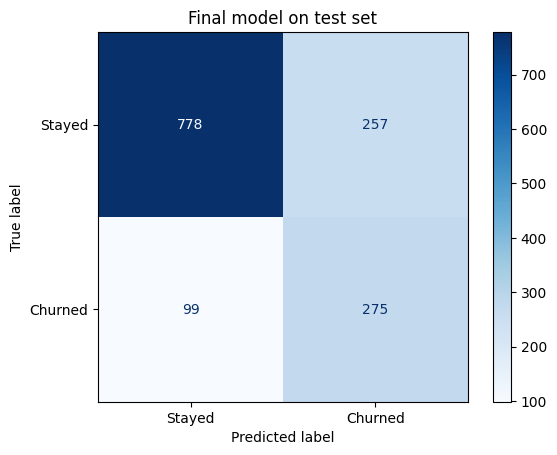

In [47]:
# The cutoff comes from training-set cross-validation only. The test set is scored ONCE, after the model is fixed.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             classification_report, ConfusionMatrixDisplay)

final_pipe = Pipeline([
    ("preprocess", make_preprocessor(X_train_model, chosen_imputer)),
    ("select", SelectKBest(f_classif, k=15)),
    ("model", clone(best_lr_model)),
])

# 1. Choose the threshold on training data only (out-of-fold probabilities)
oof = cross_val_predict(final_pipe, X_train_model, y_train, cv=cv,
                        method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
threshold = thr[f1[:-1].argmax()]
print("Chosen threshold (from CV):", round(threshold, 3))

# 2. Fit on the full training set, then evaluate on test ONCE
final_pipe.fit(X_train_model, y_train)
test_proba = final_pipe.predict_proba(X_test_model)[:, 1]
test_pred = (test_proba >= threshold).astype(int)

print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.3f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, test_proba):.3f}")
print(classification_report(y_test, test_pred, target_names=["Stayed", "Churned"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("Final model on test set")
plt.show()

In [48]:
print(f"Test F1 (churn class): {f1_score(y_test, test_pred):.3f}")

Test F1 (churn class): 0.607


### Final result on the test set

| | Result |
|---|---|
| **Final model** | Logistic Regression with class weights and 15 columns |
| **Cutoff** | 0.541, chosen from training-set cross-validation |
| **ROC-AUC** | 0.832 |
| **PR-AUC** | 0.620 |
| **F1** | 0.607 |
| **Recall** | 0.74 |
| **Precision** | 0.52 |

> **Takeaway:** the test score is a little below CV, as expected, and it was scored only once.

### SMOTE versus class weights (Logistic Regression)

In [49]:
# !pip install imbalanced-learn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

print("Final LR class_weight:", best_lr_model.class_weight)

def make_pipe(balance):
    steps = [("preprocess", make_preprocessor(X_train_model, chosen_imputer)),
             ("select", SelectKBest(f_classif, k=15))]
    model = clone(best_lr_model)
    if balance == "none":
        model.set_params(class_weight=None)
    elif balance == "class_weight":
        model.set_params(class_weight="balanced")
    elif balance == "smote":
        model.set_params(class_weight=None)
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))  # only resamples training folds
    steps.append(("model", model))
    return ImbPipeline(steps)

metrics = ["roc_auc", "average_precision", "f1", "precision", "recall"]
rows = []
for b in ["none", "class_weight", "smote"]:
    s = cross_validate(make_pipe(b), X_train_model, y_train, cv=cv, scoring=metrics, n_jobs=-1)
    rows.append({"Balancing": b, **{m: s[f"test_{m}"].mean() for m in metrics}})

pd.DataFrame(rows).set_index("Balancing").round(3)

Final LR class_weight: balanced


,roc_auc,average_precision,f1,precision,recall
Balancing,,,,,
none,0.839,0.648,0.555,0.662,0.478
class_weight,0.840,0.648,0.628,0.522,0.789
smote,0.840,0.648,0.629,0.524,0.786


### Result: SMOTE versus class weights (Logistic Regression)

| | F1 |
|---|---|
| Class weights | 0.628 |
| **SMOTE** | **0.629** |

> **Takeaway:** the same result. SMOTE does not beat class weights.

### XGBoost: number of columns and imbalance handling

In [50]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

best_xgb_model = tuning_results["XGBoost"].best_estimator_.named_steps["model"]
spw = (y_train == 0).sum() / (y_train == 1).sum()   # about 2.77
metrics = ["roc_auc", "average_precision", "f1", "precision", "recall"]

def make_xgb_pipe(k="all", balance="none"):
    steps = [("preprocess", make_preprocessor(X_train_model, chosen_imputer)),
             ("select", SelectKBest(f_classif, k=k))]
    model = clone(best_xgb_model).set_params(n_jobs=1)  # CV runs in parallel instead
    if balance == "scale_pos_weight":
        model.set_params(scale_pos_weight=spw)
    elif balance == "smote":
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return ImbPipeline(steps)

def cv_row(pipe, label):
    s = cross_validate(pipe, X_train_model, y_train, cv=cv, scoring=metrics, n_jobs=-1)
    row = {"": label, **{m: s[f"test_{m}"].mean() for m in metrics}}
    row["f1 std"] = s["test_f1"].std()
    return row

# A) How many features?
k_rows = [cv_row(make_xgb_pipe(k=k), k) for k in [5, 10, 15, 20, 25, 30, "all"]]
xgb_k_results = pd.DataFrame(k_rows).set_index("").round(3)
display(xgb_k_results)

# B) Imbalance handling (all features)
b_rows = [cv_row(make_xgb_pipe(balance=b), b) for b in ["none", "scale_pos_weight", "smote"]]
xgb_balance_results = pd.DataFrame(b_rows).set_index("").round(3)
display(xgb_balance_results)

,roc_auc,average_precision,f1,precision,recall,f1 std
,,,,,,
5,0.837,0.635,0.552,0.666,0.473,0.025
10,0.846,0.658,0.585,0.665,0.522,0.016
15,0.848,0.661,0.582,0.662,0.519,0.017
20,0.849,0.666,0.589,0.666,0.528,0.019
25,0.849,0.665,0.593,0.671,0.532,0.026
30,0.848,0.662,0.594,0.676,0.531,0.019
all,0.850,0.668,0.598,0.674,0.538,0.025


,roc_auc,average_precision,f1,precision,recall,f1 std
,,,,,,
none,0.850,0.668,0.598,0.674,0.538,0.025
scale_pos_weight,0.849,0.667,0.632,0.515,0.816,0.020
smote,0.846,0.660,0.636,0.571,0.717,0.021


### Result: SMOTE versus class weights (XGBoost)

| | F1 |
|---|---|
| Class weights (`scale_pos_weight`) | 0.632 |
| **SMOTE** | **0.636** |

> **Takeaway:** again almost the same, so the way we balance the classes barely matters. ROC-AUC stays near 0.85 for every option.

---
# Summary

### What this notebook covered

- Explored the data and the target (26.5% churn) before changing anything.
- Converted `TotalCharges` to numbers and compared median, mean and product fills for its 11 blank values.
- Merged "No internet service" / "No phone service" into "No" and one-hot encoded inside pipelines.
- Built Dummy, Logistic Regression and Random Forest baselines, then tuned Logistic Regression, Random Forest and XGBoost.
- Tested ANOVA / Chi-square feature selection, a tuned cutoff, and SMOTE versus class weights.
- Scored the final model on the test set once (ROC-AUC 0.832, F1 0.607).

Takeaway: none of the steps improved how well customers are ranked (ROC-AUC stays near 0.84). They mostly change the balance between recall and precision.